In [1]:
import sys
sys.path.append('../src/')
from plotting import *
from autocorrelations import *

import numpy as np
import matplotlib.pyplot as plt
import h5py
from pathlib import Path
import json
from scipy.optimize import curve_fit
from avalanche_analysis import *
from matplotlib.colors import LinearSegmentedColormap

%matplotlib widget




In [2]:
### Figure Settings ###

plt.rcParams['font.sans-serif'] = ['Helvetica']

legend_ax_font = 12
ax_label_font = 16
ax_title_font = 18
line_width = 2.5

minor_tick_length = 6
major_tick_length = 9
minor_tick_width = 0.75
major_tick_width = 1.0

fig_size = (8,5)

nps_custom = LinearSegmentedColormap.from_list(
  'nps_custom', [
    (0.00, '#000000'),
    (0.12, '#342c7a'),
    (0.25, '#a43479'),
    (0.55, '#d74444'),
    (0.78, '#f3de80'),
    (1.00, '#ffffff'),
], N=256
)

In [3]:
def N(t,a,c):
    return a*np.log(t) + c

def N_prime(t,a,c):
    return a/t

def N_double_prime(t,a,c):
    return -a/t**2

In [ ]:
CONFIG_FILE_NAME = "config_NPS_example.json"
Scan =796

config_file = Path('../configs/' + CONFIG_FILE_NAME)

with open(config_file, "r") as file:
    config = json.load(file)

### Output Directory ###
figure_path = config_file.parent.parent / config.get("Figures")
figure_path.mkdir(parents=True, exist_ok=True)

BASE_DIR     = Path(config.get("Base"))
dataset_path = Path(config.get(f"{Scan}"))
work_path    = BASE_DIR / dataset_path
results_path = work_path / Path(config.get("Results")) / Path(config.get(f"{Scan}_results_3"))

print(f"Results file: {results_path}")

print(f"Exists: {results_path.exists()}")

Results file: /Users/eriklamb/data/PETRA/PETRA_P10_November2023/Beamtime_11017686/raw/NPS_01_00796/e4m/results/particle2_temp405.0K_scan796_crop0x0_ms1.0_nr5ns1_bin1_st0_tb2700_newmaskTrue_tiltTrue.h5
Exists: True


In [5]:
with h5py.File(results_path, 'r') as DATA:
    C              = DATA['XPCS/TwoTime'][:]
    C_extent       = DATA['XPCS/TwoTime_extent'][:]
    mask           = DATA['XPCS/Mask'][:]
    det            = DATA['XPCS/det_corr'][:]

#Remove hot pixels
det[det>10000] = 0 

noise_D = C

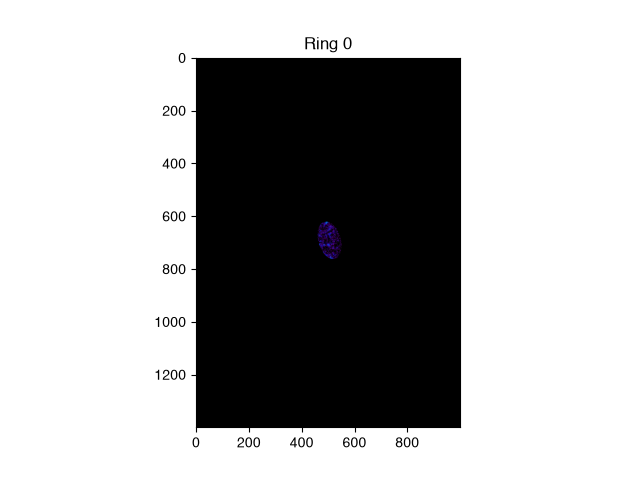

In [6]:
M = 0

# Plot ROI
fig, ax = plt.subplots()

# Overlay the second image with a 'plasma' color scale and some transparency
ax.imshow(np.sum(det[0:1,:,:],axis=0)*mask[M,:,:]+1,cmap='nipy_spectral',norm=LogNorm(vmin=1, vmax=500))

ax.set_title(f'Ring {M}')
# Display the plot
plt.show()


<function matplotlib.pyplot.show(close=None, block=None)>

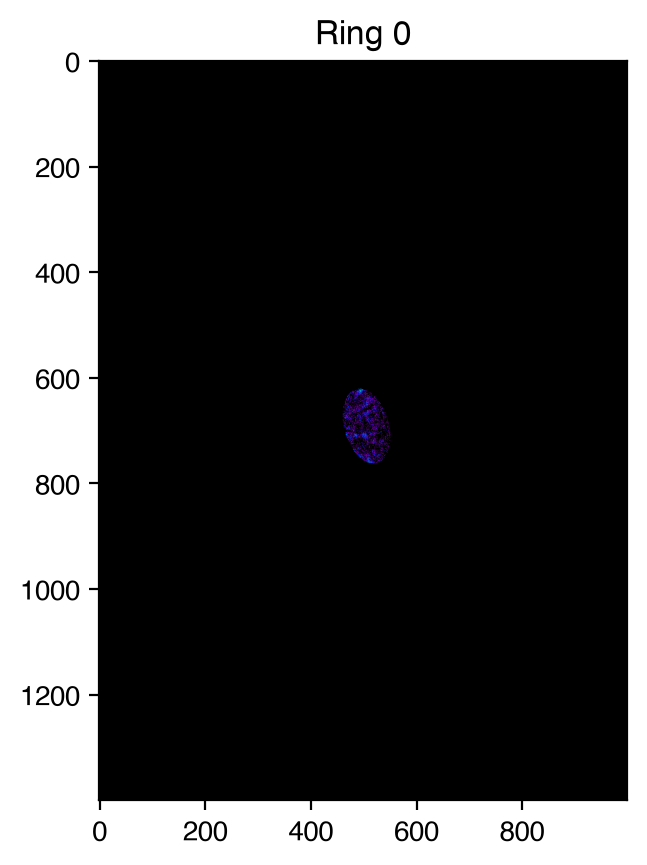

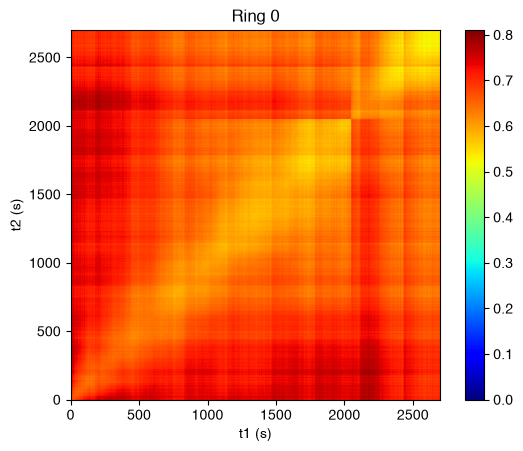

In [7]:
IMG_temp = det[:,mask[M,:,:]==1]
IMGS_NORM = IMG_temp.reshape((IMG_temp.shape[0],IMG_temp.shape[1],1))


D = diff_matrix(IMGS_NORM)#/np.size(det[:,masks[M,:,:]==1])


import matplotlib.pyplot as plt
%matplotlib inline

#C/np.size(det[:,masks[M,:,:]==1])
fig,ax = plt.subplots()
ax.set_ylabel('t2 (s)')
ax.set_xlabel('t1 (s)')
ax.set_title(f'Ring {M}')
#ax.set_title('Whole Mask')
im=ax.imshow(D,origin="lower",extent=C_extent,cmap='jet')
fig.colorbar(im, ax=ax)

plt.show

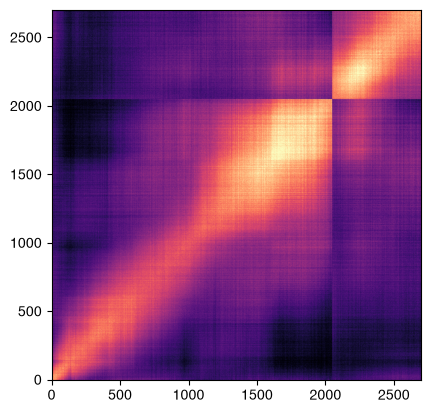

In [8]:
fig,ax = plt.subplots()

ax.imshow(noise_D, extent=C_extent,origin='lower', cmap='magma',vmin=0,vmax=1)

<>:22: SyntaxWarning: invalid escape sequence '\s'
<>:22: SyntaxWarning: invalid escape sequence '\s'
/var/folders/jg/p8s420v17f3064xm8v_n78s00000gn/T/ipykernel_69246/3914193108.py:22: SyntaxWarning: invalid escape sequence '\s'
  ax2.set_ylabel("$A(t_{age})$ ($\sigma$)",fontsize=ax_label_font+4)


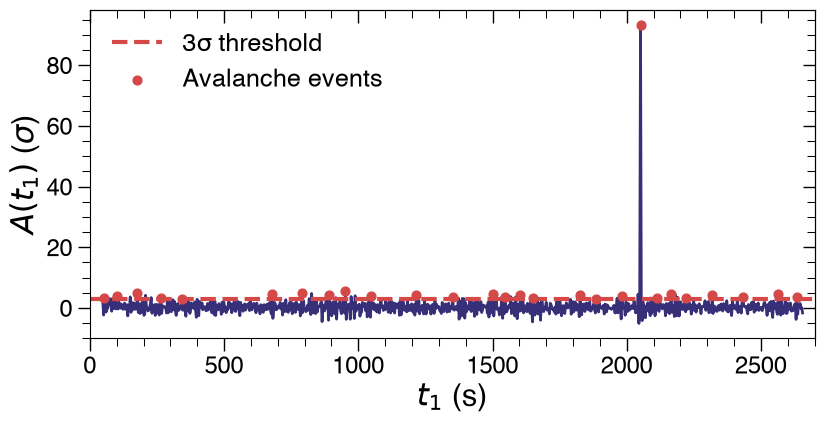

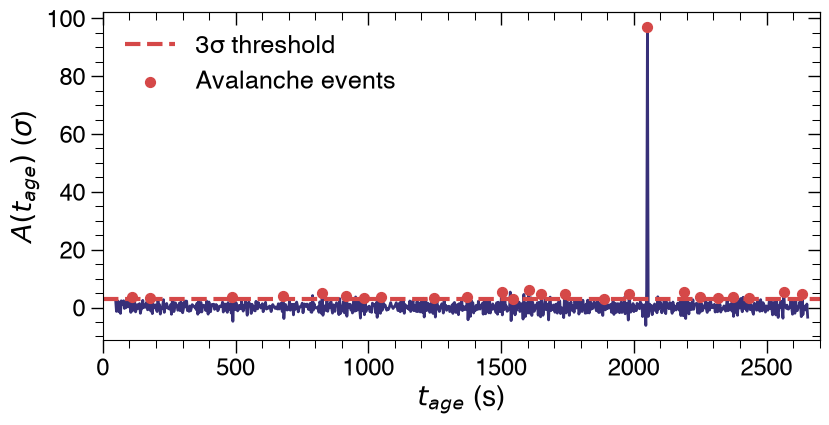

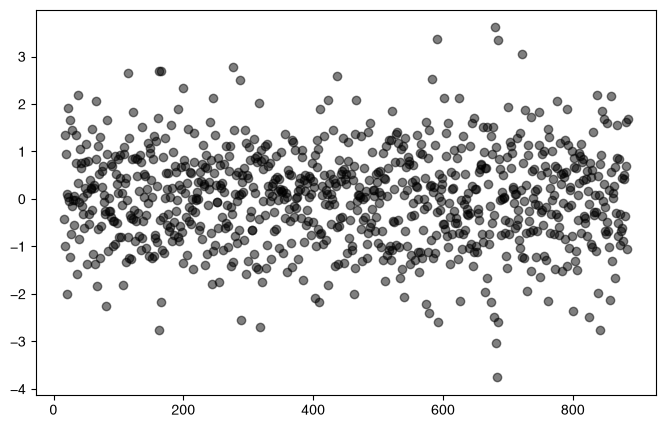

In [9]:
# If your two-time is a correlation matrix (values ~0 to 1):


sigma_threshold = 3

fig,ax = plt.subplots(1,1,figsize=(8,4))
fig2,ax2 = plt.subplots(1,1,figsize=(8,4))
fig3,ax3 = plt.subplots(1,1,figsize=fig_size)

#D and C consistent with each other check
result = sutton_avalanche_pipeline(D, m=15, sigma_threshold=sigma_threshold,min_separation=15,min_prominence=0.0)
resultC = avalanche_from_C2(C, m=15, sigma_threshold=sigma_threshold,min_separation=15,min_prominence=0.0)

#Plot D and C
t = np.linspace(C_extent[2], C_extent[3], C.shape[1])
fig = plot_sutton_analysis(C, result, times=t,sigma_threshold=sigma_threshold,ttc=False,fig=fig,ax=ax,line_width=3)
ax.set_xlabel(r"$t_1$ (s)",fontsize=ax_label_font+6)
ax.set_ylabel(r"$A(t_1)$ ($\sigma$)",fontsize=ax_label_font+6)

fig2 = plot_sutton_analysis(C, resultC, times=t,sigma_threshold=sigma_threshold,ttc=False,fig=fig2,ax=ax2,line_width=3,marker_size=50)
ax2.set_xlabel("$t_{age}$ (s)",fontsize=ax_label_font+4)
ax2.set_ylabel("$A(t_{age})$ ($\sigma$)",fontsize=ax_label_font+4)

#Difference between D and C
ax3.plot(result['A_norm']-resultC['A_norm'],'o',color='black',alpha=0.5)

axt, axr = asymmetric_ticks(ax,major_len=major_tick_length, minor_len=minor_tick_length, major_w=major_tick_width, minor_w=minor_tick_width, labelsize=legend_ax_font+5)
axt, axr = asymmetric_ticks(ax2,major_len=major_tick_length, minor_len=minor_tick_length, major_w=major_tick_width, minor_w=minor_tick_width, labelsize=legend_ax_font+5)


ax.legend(fontsize=legend_ax_font+6,frameon=False)
ax2.legend(fontsize=legend_ax_font+6,frameon=False)

fig2.savefig(figure_path / "avalanche_detection.pdf",format="pdf",dpi=600,bbox_inches="tight",metadata={'Creator': ''})

# Loop Through All Cs

<>:40: SyntaxWarning: invalid escape sequence '\s'
<>:40: SyntaxWarning: invalid escape sequence '\s'
/var/folders/jg/p8s420v17f3064xm8v_n78s00000gn/T/ipykernel_69246/997088707.py:40: SyntaxWarning: invalid escape sequence '\s'
  ax[k,j].set_ylabel("$A(t_{age})$ ($\sigma$)",fontsize=ax_label_font)


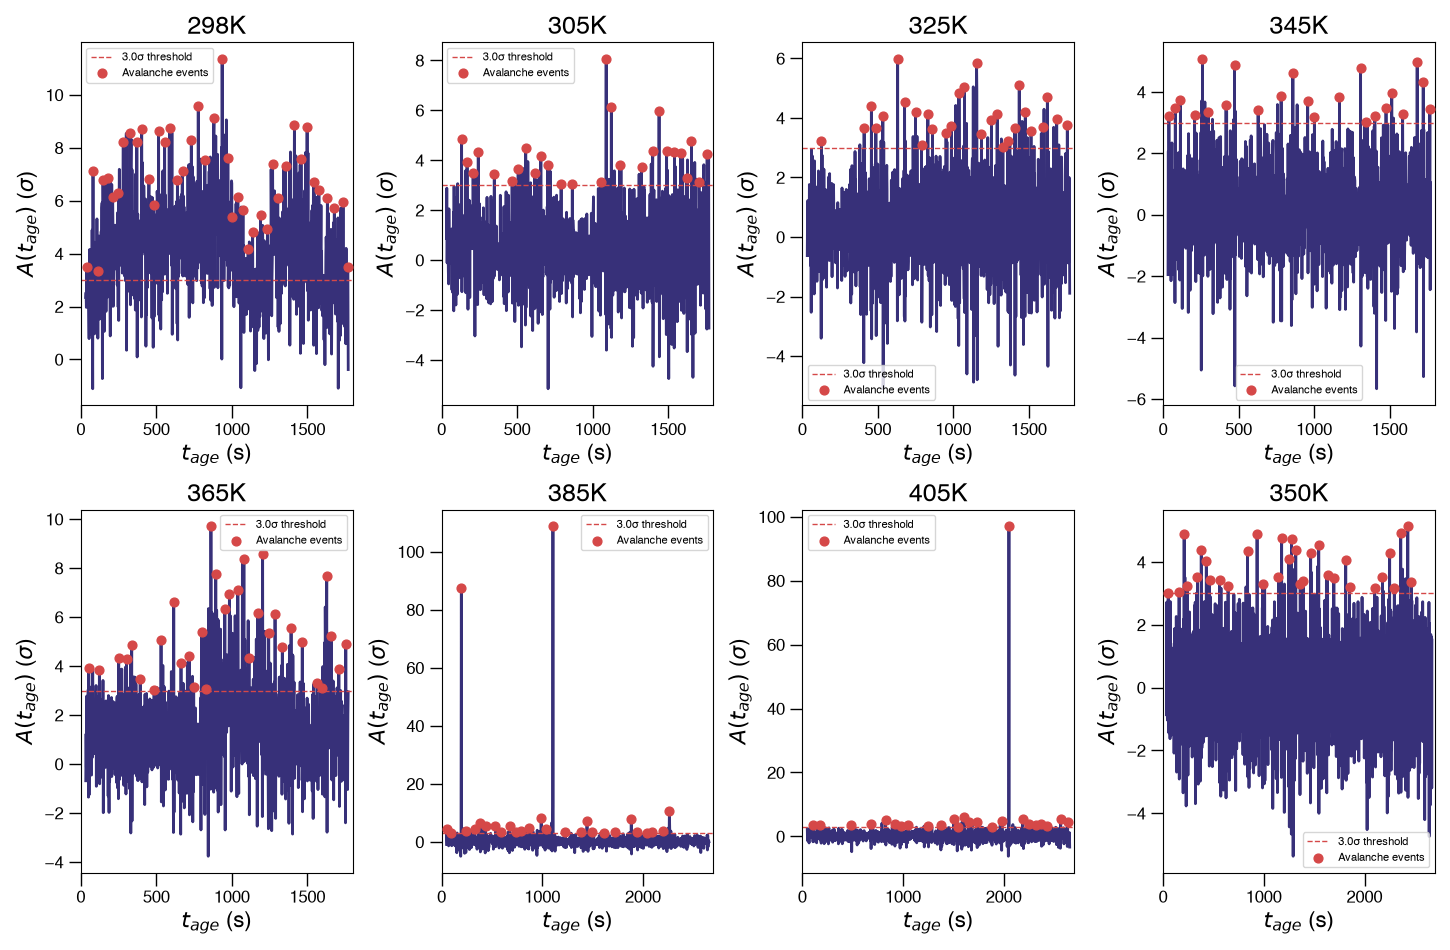

In [10]:
# If your two-time is a correlation matrix (values ~0 to 1):
sigma_threshold = 3.0
min_separation = 15
min_window = 15
%matplotlib widget


fig, ax = plt.subplots(2, 4, figsize=(14.5, 9.5))  # Adjusted width and height of subplots grid

scans = [219, 334, 552, 579, 709, 779, 796, 868]
Temperature = [298, 305, 325, 345, 365, 385, 405, 350]

for i,Scan in enumerate(scans):

    j = i%4

    if i ==0 and j ==0:
        k=0
    elif i !=0 and j ==0:
        k=1


    BASE_DIR     = Path(config.get("Base"))
    dataset_path = Path(config.get(f"{Scan}"))
    work_path    = BASE_DIR / dataset_path
    results_path = work_path / Path(config.get("Results")) / Path(config.get(f"{Scan}_results_3"))


    with h5py.File(results_path, 'r') as DATA:
        C              = DATA['XPCS/TwoTime'][:]
        C_extent       = DATA['XPCS/TwoTime_extent'][:]



    result = avalanche_from_C2(C, m=min_window, sigma_threshold=sigma_threshold,min_separation=min_separation,min_prominence=0.0)

    t = np.linspace(C_extent[2], C_extent[3], C.shape[1])
    fig = plot_sutton_analysis(C, result, times=t,sigma_threshold=sigma_threshold,ttc=False,fig=fig,ax=ax[k,j])
    ax[k,j].set_xlabel("$t_{age}$ (s)",fontsize=ax_label_font)
    ax[k,j].set_ylabel("$A(t_{age})$ ($\sigma$)",fontsize=ax_label_font)
    ax[k,j].set_title(f"{Temperature[i]}K",fontsize=ax_title_font)

    ax[k,j].tick_params(which='major', length=major_tick_length, width=major_tick_width, labelsize=legend_ax_font)
    ax[k,j].tick_params(which='minor', length=minor_tick_length, width=minor_tick_width,labelsize=legend_ax_font)


plt.show()

fig.savefig(figure_path / "avalanche_detection_all.pdf",format="pdf",dpi=300,bbox_inches="tight",metadata={'Creator': ''})

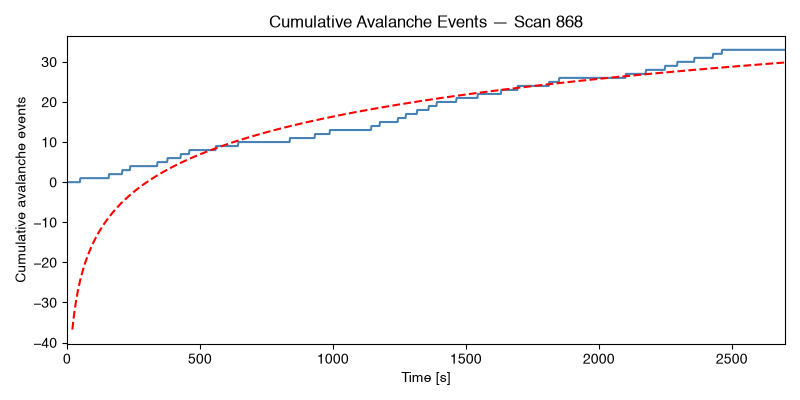

In [11]:
avalanche_mask = np.zeros(C.shape[0], dtype=int)
avalanche_mask[result['avalanche_times']] = 1
cumulative_events = np.cumsum(avalanche_mask)

popt,pcov = curve_fit(N, t[100:], cumulative_events[100:],p0=[10,1])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(t, cumulative_events, color='steelblue', lw=1.5)
ax.plot(t[10:], N(t[10:], *popt), 'r--', label=f'Fit: {popt[0]:.2f}*ln(t) + {popt[1]:.2f}')

ax.set_xlabel('Time [s]')
ax.set_ylabel('Cumulative avalanche events')
ax.set_title(f'Cumulative Avalanche Events — Scan {Scan}')
ax.set_xlim(t[0], t[-1])
fig.tight_layout()
plt.show()

Scan 219 (298 K): 45 events
Scan 334 (305 K): 27 events
Scan 552 (325 K): 24 events
Scan 579 (345 K): 28 events
Scan 709 (365 K): 35 events
Scan 779 (385 K): 23 events
Scan 796 (405 K): 22 events
Scan 868 (350 K): 36 events


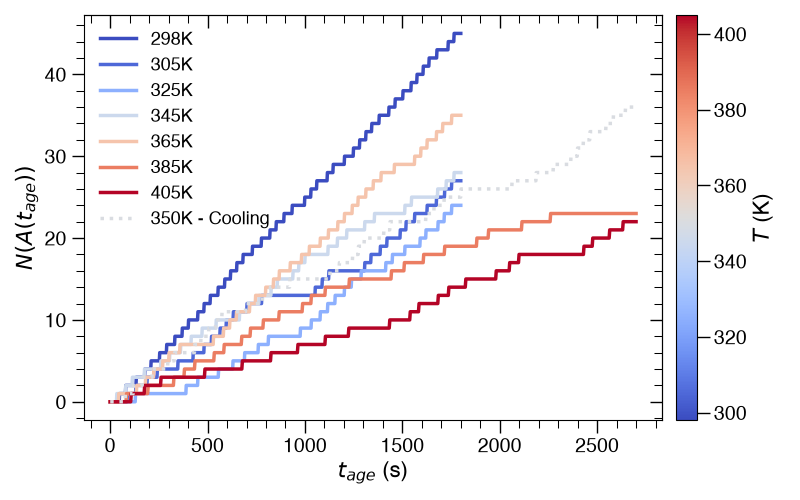

In [12]:
scans = [219, 334, 552, 579, 709, 779, 796, 868]
min_separation = 15
sigma_threshold = 3.0
min_window = 15

from matplotlib.colors import LinearSegmentedColormap, Normalize

temps = np.array([298, 305, 325, 345, 350, 365, 385, 405])
colors = ['#074a54', '#1c94b0', '#6abce7', '#9c86e3',
          '#ee8bb6', '#f27086', '#da499d']

cmap = LinearSegmentedColormap.from_list('temp_series', colors)

# Option A: physically spaced — color position proportional to T
norm = Normalize(vmin=temps.min(), vmax=temps.max())
temp_colors = {T: cmap(norm(T)) for T in temps}

# First pass: gather valid scans and temperatures for consistent normalization
valid_scans = []
for scan in scans:
    scan_path = config.get(f"{scan}")
    results_file = config.get(f"{scan}_results")
    temp = config.get(f"{scan}_temperature")

    if scan_path is None or results_file is None or temp is None:
        print(f"Scan {scan}: missing config entry, skipping")
        continue

    rpath = BASE_DIR / Path(scan_path) / Path(config.get("Results")) / Path(results_file)
    if not rpath.exists():
        print(f"Scan {scan}: file not found, skipping")
        continue

    valid_scans.append((scan, float(temp), rpath))

if not valid_scans:
    raise RuntimeError("No valid scans found for cumulative avalanche plot.")

temps = np.array([t for _, t, _ in valid_scans], dtype=float)
cmap = plt.cm.coolwarm
norm = plt.Normalize(vmin=temps.min(), vmax=temps.max())

fig, ax = plt.subplots(figsize=fig_size)

for scan, temp, rpath in valid_scans:
    with h5py.File(rpath, "r") as DATA:
        C_scan = DATA["XPCS/TwoTime"][:]
        C_ext = DATA["XPCS/TwoTime_extent"][:]

    res = avalanche_from_C2(
        C_scan,
        m=min_window,
        sigma_threshold=sigma_threshold,
        min_separation=min_separation,
        min_prominence=0.0,
    )
    t_scan = np.linspace(C_ext[2], C_ext[3], C_scan.shape[1])

    mask = np.zeros(C_scan.shape[0], dtype=int)
    mask[res["avalanche_times"]] = 1
    cumulative = np.cumsum(mask)

    if scan != 868:
        ax.plot(
            t_scan,
            cumulative,
            lw=line_width,
            color=cmap(norm(temp)),
            label=f"{temp:.0f}K",
            )

    if scan == 868:
        ax.plot(
            t_scan,
            cumulative,
            linestyle='dotted',
            lw=line_width,
            color=cmap(norm(temp)),
            label=f"{temp:.0f}K - Cooling",
        )
    print(f"Scan {scan} ({temp:.0f} K): {len(res['avalanche_times'])} events")

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label("$T$ (K)",fontsize=ax_label_font)
cbar.ax.tick_params(
            which="major", length=major_tick_length, width=major_tick_width, labelsize=legend_ax_font+2
        )
cbar.ax.tick_params(
            which="minor", length=minor_tick_length, width=minor_tick_width, labelsize=legend_ax_font+2
        )

ax.set_xlabel("$t_{age}$ (s)",fontsize=ax_label_font)
ax.set_ylabel("$N(A(t_{age}))$",fontsize=ax_label_font)

axt, axr = asymmetric_ticks(ax,major_len=major_tick_length, minor_len=minor_tick_length, major_w=major_tick_width, minor_w=minor_tick_width, labelsize=legend_ax_font+2)

ax.legend(fontsize=legend_ax_font+1, frameon=False,loc='upper left')
fig.tight_layout()
plt.show()



fig.savefig(
    figure_path / "cumulative_avalanche_events.pdf",
    format="pdf",
    dpi=300,
    bbox_inches="tight",
    metadata={"Creator": ""},
)


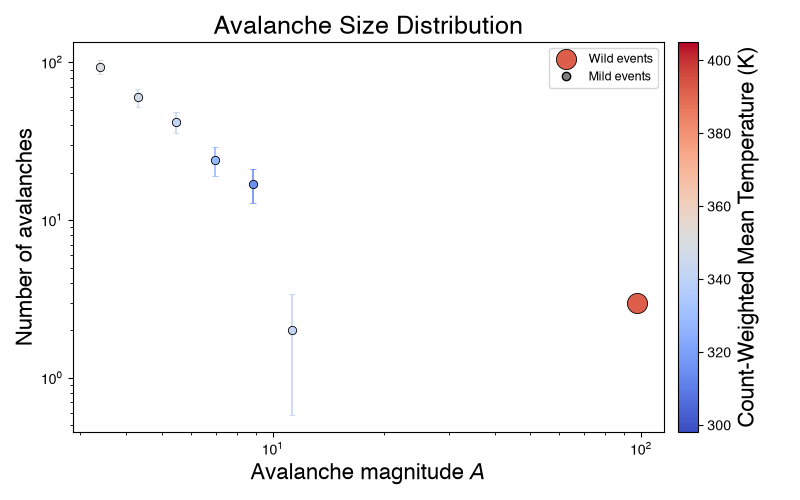

Temperature range: 298–405 K
Total events: 242
Maximum Avalachnce: 108


In [13]:
scans = [219, 334, 552, 579, 709, 779, 796,868]
sigma_threshold = 3.0
m_window = 15
n_bins = 15
min_separation = 15
DorC = 'C'

# Mild / wild regions (same as next cell)
x_mild = (3.0, 13)
x_wild = (13, 130.0)

mags_all = []
per_scan = []  # (temperature_K, magnitudes)

for scan in scans:
    scan_path = config.get(f"{scan}")
    results_file = config.get(f"{scan}_results_3")
    temp = config.get(f"{scan}_temperature")

    if scan_path is None or results_file is None or temp is None:
        continue

    rpath = BASE_DIR / Path(scan_path) / Path(config.get("Results")) / Path(results_file)
    if not rpath.exists():
        continue

    with h5py.File(rpath, "r") as DATA:
        C_scan = DATA["XPCS/TwoTime"][:]
        mask   = DATA['XPCS/Mask'][:]
        
        if DorC == 'D':
            det    = DATA['XPCS/det_corr'][:]

            #Remove hot pixels
            det[det>10000] = 0 

            IMG_temp = det[:,mask[M,:,:]==1]
            #IMG_temp = det[:,mask_sum>0]
            IMGS_NORM = IMG_temp.reshape((IMG_temp.shape[0],IMG_temp.shape[1],1))

            D = diff_matrix(IMGS_NORM)#/np.size(det[:,masks[M,:,:]==1])

    if DorC == 'C':
        res = avalanche_from_C2(
            C_scan,
            m=m_window,
            sigma_threshold=sigma_threshold,
            min_separation=min_separation,
            min_prominence=0.0,
        )
    if DorC == 'D':
        res = sutton_avalanche_pipeline(
            D, 
            m=m_window, 
            sigma_threshold=sigma_threshold,
            min_separation=min_separation,
            min_prominence=0.0)
    
    magnitudes = np.asarray(res["avalanche_amplitudes"], dtype=float)
    magnitudes = magnitudes[np.isfinite(magnitudes)]
    magnitudes = magnitudes[magnitudes > 0]

    if magnitudes.size == 0:
        continue

    T = float(temp)
    per_scan.append((T, magnitudes))
    mags_all.append(magnitudes)

if not mags_all:
    raise RuntimeError("No avalanche magnitudes for any scan — check paths / data.")

mags_ref = np.concatenate(mags_all)
glob_min = mags_ref.min()
glob_max = mags_ref.max()

x_wild = (13, glob_max * 1.01)   # or (13, 130.0)

bin_edges = np.logspace(np.log10(glob_min), np.log10(glob_max * 1.01), n_bins + 1)

#bin_edges = np.logspace(np.log10(glob_min), np.log10(glob_max), n_bins + 1)
bin_centers_full = np.sqrt(bin_edges[:-1] * bin_edges[1:])
# Total counts and count-weighted mean temperature per bin
counts_full = np.zeros(n_bins, dtype=float)
temp_weighted_sum = np.zeros(n_bins, dtype=float)

for T, mags in per_scan:
    hist, _ = np.histogram(mags, bins=bin_edges)
    counts_full += hist
    temp_weighted_sum += T * hist

keep = counts_full > 0
bin_centers = bin_centers_full[keep]
counts = counts_full[keep]
bin_temp = temp_weighted_sum[keep] / counts  # count-weighted mean T per bin

T_min = min(T for T, _ in per_scan)
T_max = max(T for T, _ in per_scan)
#cmap = plt.cm.coolwarm
#norm = plt.Normalize(vmin=T_min, vmax=T_max)
face_colors = cmap(norm(bin_temp))

mild_mask = (bin_centers > x_mild[0]) & (bin_centers < x_mild[1])
wild_mask = (bin_centers > x_wild[0]) & (bin_centers < x_wild[1])

fig, ax = plt.subplots(figsize=(8, 5))

# Wild events: markers only (low statistics per bin)
if np.any(wild_mask):
    ax.scatter(
        bin_centers[wild_mask],
        counts[wild_mask],
        s=210*k**2, linewidths=0.6*k,
        c=face_colors[wild_mask],
        edgecolors="black",
        zorder=3,
        label="Wild events",
    )

# Mild events: Poisson error bars (per-bin colors; errorbar needs one color at a time)
if np.any(mild_mask):
    for xc, yc, sy, fc in zip(
        bin_centers[mild_mask],
        counts[mild_mask],
        np.sqrt(counts[mild_mask]),
        face_colors[mild_mask],
    ):
        ax.errorbar(
            xc,
            yc,
            yerr=sy,
            fmt="o",
            ms=6,
            color=fc,
            ecolor=fc,
            markeredgecolor="black",
            markeredgewidth=0.6,
            capsize=2,
            elinewidth=1.2,
            zorder=4,
        )
    ax.plot([], [], "o", color="gray", markeredgecolor="black", label="Mild events")

ax.set_yscale("log")
ax.set_xscale("log")
ax.set_xlabel("Avalanche magnitude $A$",fontsize=16)
ax.set_ylabel("Number of avalanches",fontsize=16)
ax.set_title(f"Avalanche Size Distribution",fontsize=18)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label("Count-Weighted Mean Temperature (K)",fontsize=16)

ax.legend(fontsize=9, loc="upper right")
#ax.set_ylim(-0.5, 100)
#ax.set_xlim(2.5, 120)
fig.tight_layout()
plt.show()

print(f"Temperature range: {T_min:.0f}–{T_max:.0f} K")
print(f"Total events: {int(mags_ref.size)}")
print(f"Maximum Avalachnce: {int(mags_ref.max())}")

<>:139: SyntaxWarning: invalid escape sequence '\s'
<>:139: SyntaxWarning: invalid escape sequence '\s'
/var/folders/jg/p8s420v17f3064xm8v_n78s00000gn/T/ipykernel_69246/1442280589.py:139: SyntaxWarning: invalid escape sequence '\s'
  ax.set_xlabel("$A$ $(\sigma)$", fontsize=16)
/var/folders/jg/p8s420v17f3064xm8v_n78s00000gn/T/ipykernel_69246/1442280589.py:142: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  ax.set_ylim(0.0, 130)


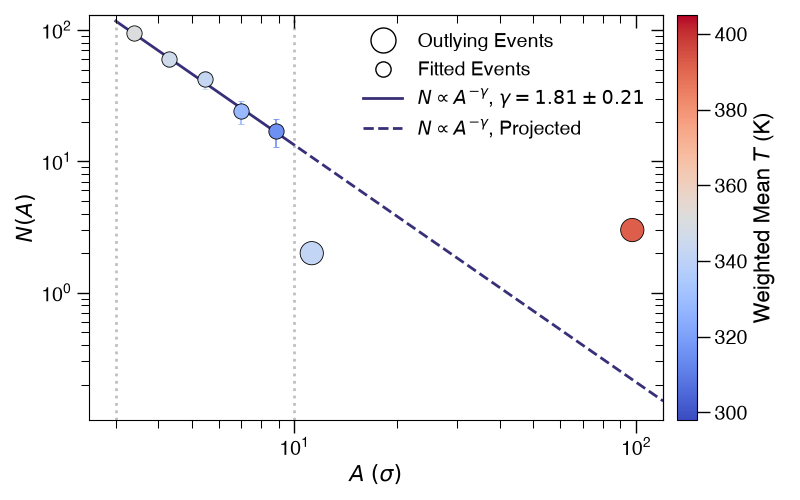

gamma = 1.805 +/- 0.214  (power-law fit in count space with Poisson weights)


In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
%matplotlib widget


def power_law(x, a, gamma):
    return a * x**(-gamma)



# physically motivated cutoffs: exclude the head (threshold-shaped)
# and the three depinning events at large A
x_min1 = 3.0     # above the detection-threshold-shaped head
x_max1 = 9.96   # below the depinning events
x_min3 = 10.25  #12.5
x_max3 = 120.0

mask1 = (bin_centers > x_min1) & (bin_centers < x_max1) & (counts > 0)
mask3 = (bin_centers > x_min3) & (bin_centers < x_max3) & (counts > 0)


# Poisson uncertainty for mild-event bins only (wild tail has too few counts per bin)
sigma_counts1 = np.sqrt(counts[mask1])

# Initial guess from log-log slope
_x = bin_centers[mask1]
_y = counts[mask1]
_slope, _intercept = np.polyfit(np.log(_x), np.log(_y), 1)
p0 = [np.exp(_intercept), -_slope]

# Fit in count space using Poisson uncertainties
popt1, pcov1 = curve_fit(
    power_law,
    _x,
    _y,
    p0=p0,
    sigma=sigma_counts1,
    absolute_sigma=True,
    bounds=([0, 0], [np.inf, np.inf]),
)
a_fit1, gamma_fit1 = popt1
perr1 = np.sqrt(np.diag(pcov1))

# Build fit line over the actual fit range
A_fit1 = np.geomspace(x_min1, x_max1, 100)
A_fit2 = np.geomspace(x_min3, x_max3, 100)

N_fit1 = power_law(A_fit1, *popt1)
N_fit2 = power_law(A_fit2, *popt1)
"""""

def power_law(x, a):
    return a * x**(-3)

# Fit in count space using Poisson uncertainties
popt1, pcov1 = curve_fit(
    power_law,
    _x,
    _y,
    p0=[1],
    sigma=sigma_counts1,
    absolute_sigma=True,
    bounds=([0], [np.inf]),
)

# Build fit line over the actual fit range
A_fit1 = np.geomspace(x_min1, x_max1, 100)
N_fit1 = power_law(A_fit1, popt1[0])
"""""

fig, ax = plt.subplots(figsize=fig_size)

# Temperature colors from previous cell (count-weighted mean T per bin)
colors_mild = face_colors[mask1]
colors_wild = face_colors[mask3]

# Wild events: markers only (1–2 counts/bin; Poisson bars are not informative)
if np.any(mask3):
    ax.scatter(
        bin_centers[mask3],
        counts[mask3],
        s=280,
        c=colors_wild,
        edgecolors="black",
        linewidths=0.6,
        zorder=3,
        #label="Rare Events",
    )
    ax.plot([], [], "o",ms=18,color="none", markeredgecolor="black", label="Outlying Events")


# Mild events: per-bin temperature colors
if np.any(mask1):
    for xc, yc, sy, fc in zip(
        bin_centers[mask1],
        counts[mask1],
        sigma_counts1,
        colors_mild,
    ):
        ax.errorbar(
            xc,
            yc,
            yerr=sy,
            fmt="o",
            ms=11,
            color=fc,
            ecolor=fc,
            markeredgecolor="black",
            markeredgewidth=0.6,
            capsize=2,
            elinewidth=1.2,
            zorder=4,
        )
    ax.plot([], [], "o",ms=11, color="none", markeredgecolor="black", label="Fitted Events")

ax.loglog(
    A_fit1,
    N_fit1,
    "-",
    color="#373079",
    lw=2,
    label=rf"$N \propto A^{{-\gamma}}$, $\gamma={popt1[1]:.2f} \pm {perr1[1]:.2f}$",
)

ax.loglog(
    A_fit2,
    N_fit2,
    "--",
    color="#373079",
    lw=2,
    label=rf"$N \propto A^{{-\gamma}}$, Projected",
)

ax.axvline(x_min1, color="gray", ls=":",lw=2, alpha=0.5)
ax.axvline(x_max1, color="gray", ls=":",lw=2, alpha=0.5)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("$A$ $(\sigma)$", fontsize=16)
ax.set_ylabel("$N(A)$", fontsize=16)
#ax.set_title("Avalanche Size Distribution", fontsize=ax_title_font)
ax.set_ylim(0.0, 130)
ax.set_xlim(2.5, 120)

### Tick Parameters ###
#ax.tick_params(axis='both', which='major', labelsize=legend_ax_font)
#ax.tick_params(axis='both', which='minor', labelsize=legend_ax_font)


#ax.tick_params(which='major', length=major_tick_length, width=major_tick_width, labelsize=legend_ax_font)
#ax.tick_params(which='minor', length=minor_tick_length, width=minor_tick_width,labelsize=legend_ax_font)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label("Weighted Mean $T$ (K)",fontsize=ax_label_font)
cbar.ax.tick_params(
            which="major", length=major_tick_length, width=major_tick_width, labelsize=legend_ax_font+2
        )
cbar.ax.tick_params(
            which="minor", length=minor_tick_length, width=minor_tick_width, labelsize=legend_ax_font+2
        )

axt, axr = asymmetric_ticks(ax,major_len=major_tick_length, minor_len=minor_tick_length, major_w=major_tick_width, minor_w=minor_tick_width, labelsize=legend_ax_font+2)

ax.legend(fontsize=legend_ax_font+2,frameon=False,)
fig.tight_layout()
plt.show()


print(f"gamma = {gamma_fit1:.3f} +/- {perr1[1]:.3f}  (power-law fit in count space with Poisson weights)")

fig.savefig(figure_path / "avalanche_size_distribution.pdf", format="pdf", dpi=300, bbox_inches="tight", metadata={'Creator': ''})

Scan 219 (298 K): N=45, mean=6.522, SEM=0.256
Scan 334 (305 K): N=27, mean=3.955, SEM=0.150
Scan 552 (325 K): N=24, mean=4.039, SEM=0.176
Scan 579 (345 K): N=28, mean=3.817, SEM=0.128
Scan 709 (365 K): N=35, mean=5.042, SEM=0.246
Scan 779 (385 K): N=23, mean=13.476, SEM=6.020
Scan 796 (405 K): N=22, mean=8.420, SEM=4.696
Scan 868 (350 K): N=36, mean=3.830, SEM=0.096


<>:85: SyntaxWarning: invalid escape sequence '\s'
<>:85: SyntaxWarning: invalid escape sequence '\s'
/var/folders/jg/p8s420v17f3064xm8v_n78s00000gn/T/ipykernel_69246/240741212.py:85: SyntaxWarning: invalid escape sequence '\s'
  ax.set_ylabel('Average Avalanche Magnitude ($\sigma$)',fontsize=ax_label_font)


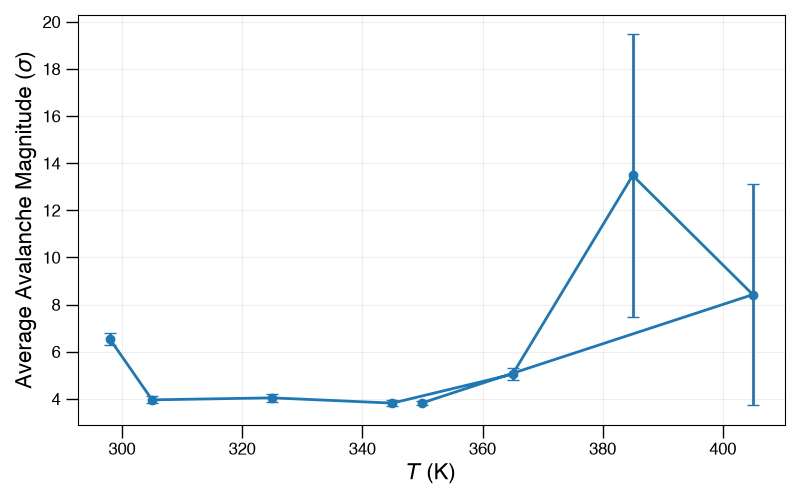

'""\nfig.savefig(\n    figure_path / \'average_avalanche_magnitude_vs_temperature.pdf\',\n    format=\'pdf\',\n    dpi=300,\n    bbox_inches=\'tight\',\n    metadata={\'Creator\': \'\'},\n)\n'

In [15]:
# Average avalanche magnitude per scan vs temperature
scans = [219, 334, 552, 579, 709, 779, 796,868]
sigma_threshold = 3
min_separation = 15

temps = []
mean_mags = []
sem_mags = []
scan_ids = []

for scan in scans:
    scan_path = config.get(f"{scan}")
    results_file = config.get(f"{scan}_results")
    temp = config.get(f"{scan}_temperature")

    if scan_path is None or results_file is None or temp is None:
        print(f"Scan {scan}: missing config entry, skipping")
        continue

    rpath = BASE_DIR / Path(scan_path) / Path(config.get("Results")) / Path(results_file)
    if not rpath.exists():
        print(f"Scan {scan}: file not found, skipping")
        continue

    with h5py.File(rpath, 'r') as DATA:
        C_scan = DATA['XPCS/TwoTime'][:]

    res = avalanche_from_C2(
        C_scan,
        m=15,
        sigma_threshold=sigma_threshold,
        min_separation=min_separation,
        min_prominence=0.0,
    )

    av_times = res['avalanche_times']
    if len(av_times) == 0:
        print(f"Scan {scan} ({temp} K): no avalanches found")
        continue

    magnitudes = np.asarray(res['A_norm'][av_times], dtype=float)
    magnitudes = magnitudes[np.isfinite(magnitudes)]
    magnitudes = magnitudes[magnitudes > 0]

    if magnitudes.size == 0:
        print(f"Scan {scan} ({temp} K): no positive magnitudes, skipping")
        continue

    temps.append(float(temp))
    mean_mags.append(np.mean(magnitudes))
    sem_mags.append(np.std(magnitudes, ddof=1) / np.sqrt(magnitudes.size) if magnitudes.size > 1 else 0.0)
    scan_ids.append(scan)

    print(
        f"Scan {scan} ({temp} K): N={magnitudes.size}, "
        f"mean={mean_mags[-1]:.3f}, SEM={sem_mags[-1]:.3f}"
    )

if len(temps) == 0:
    raise RuntimeError("No valid scans with avalanche magnitudes found.")

# Sort by temperature for plotting
order = np.argsort(temps)
temps = np.asarray(temps)#[order]
mean_mags = np.asarray(mean_mags)#[order]
sem_mags = np.asarray(sem_mags)#[order]
scan_ids = np.asarray(scan_ids)#[order]

fig, ax = plt.subplots(figsize=fig_size)
ax.errorbar(
    temps,
    mean_mags,
    yerr=sem_mags,
    fmt='o-',
    capsize=4,
    lw=2,
    color='tab:blue',
    ecolor='tab:blue',
)

#for T, m, sid in zip(temps, mean_mags, scan_ids):
    #ax.annotate(str(sid), (T, m), xytext=(4, 4), textcoords='offset points', fontsize=legend_ax_font)

ax.set_xlabel('$T$ (K)',fontsize=ax_label_font)
ax.set_ylabel('Average Avalanche Magnitude ($\sigma$)',fontsize=ax_label_font)
#ax.set_title('Average Avalanche Magnitude vs Temperature',fontsize=ax_title_font)
ax.tick_params(which='major', length=major_tick_length, width=major_tick_width, labelsize=legend_ax_font)
ax.tick_params(which='minor', length=minor_tick_length, width=minor_tick_width,labelsize=legend_ax_font)

ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

"""""
fig.savefig(
    figure_path / 'average_avalanche_magnitude_vs_temperature.pdf',
    format='pdf',
    dpi=300,
    bbox_inches='tight',
    metadata={'Creator': ''},
)
"""""

Scan 219 (298 K): events=45, duration=1800.00 s, rate=0.0250 s^-1
Scan 334 (305 K): events=27, duration=1800.00 s, rate=0.0150 s^-1
Scan 552 (325 K): events=24, duration=1800.00 s, rate=0.0133 s^-1
Scan 579 (345 K): events=28, duration=1800.00 s, rate=0.0156 s^-1
Scan 709 (365 K): events=35, duration=1800.00 s, rate=0.0194 s^-1
Scan 779 (385 K): events=23, duration=2700.00 s, rate=0.0085 s^-1
Scan 796 (405 K): events=22, duration=2700.00 s, rate=0.0081 s^-1
Scan 868 (350 K): events=36, duration=2700.00 s, rate=0.0133 s^-1


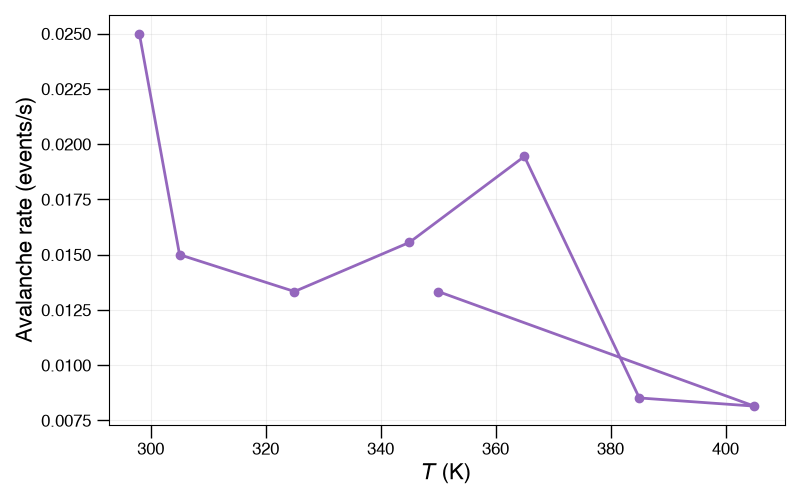

'""\nfig.savefig(\n    figure_path / \'avalanche_rate_vs_temperature.pdf\',\n    format=\'pdf\',\n    dpi=300,\n    bbox_inches=\'tight\',\n    metadata={\'Creator\': \'\'},\n)\n'

In [16]:
# Avalanche rate per scan vs temperature (using same scan set)
scans = [219, 334, 552, 579, 709, 779, 796,868]
sigma_threshold = 3
min_separation = 15

temps = []
rates = []
scan_ids = []

for scan in scans:
    scan_path = config.get(f"{scan}")
    results_file = config.get(f"{scan}_results")
    temp = config.get(f"{scan}_temperature")

    if scan_path is None or results_file is None or temp is None:
        print(f"Scan {scan}: missing config entry, skipping")
        continue

    rpath = BASE_DIR / Path(scan_path) / Path(config.get("Results")) / Path(results_file)
    if not rpath.exists():
        print(f"Scan {scan}: file not found, skipping")
        continue

    with h5py.File(rpath, 'r') as DATA:
        C_scan = DATA['XPCS/TwoTime'][:]
        C_ext = DATA['XPCS/TwoTime_extent'][:]

    res = avalanche_from_C2(
        C_scan,
        m=15,
        sigma_threshold=sigma_threshold,
        min_separation=min_separation,
        min_prominence=0.0,
    )

    

    n_events = len(res['avalanche_times'])
    total_time = float(C_ext[3] - C_ext[2])

    if total_time <= 0:
        print(f"Scan {scan} ({temp} K): non-positive duration, skipping")
        continue

    rate = n_events / total_time  # events per second

    temps.append(float(temp))
    rates.append(rate)
    scan_ids.append(scan)

    print(f"Scan {scan} ({temp} K): events={n_events}, duration={total_time:.2f} s, rate={rate:.4f} s^-1")

if len(temps) == 0:
    raise RuntimeError("No valid scans for avalanche-rate plot.")

# Sort by temperature
#order = np.argsort(temps)
temps = np.asarray(temps)#[order]
rates = np.asarray(rates)#[order]
scan_ids = np.asarray(scan_ids)#[order]

fig, ax = plt.subplots(figsize=fig_size)
ax.plot(temps, rates, 'o-', lw=2, color='tab:purple')

#for T, r, sid in zip(temps, rates, scan_ids):
    #ax.annotate(str(sid), (T, r), xytext=(4, 4), textcoords='offset points', fontsize=8)

ax.set_xlabel('$T$ (K)',fontsize=ax_label_font)
ax.set_ylabel('Avalanche rate (events/s)',fontsize=ax_label_font)
#ax.set_title('Avalanche Rate vs Temperature',fontsize=ax_title_font)
ax.tick_params(which='major', length=major_tick_length, width=major_tick_width, labelsize=legend_ax_font)
ax.tick_params(which='minor', length=minor_tick_length, width=minor_tick_width,labelsize=legend_ax_font)

ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

"""""
fig.savefig(
    figure_path / 'avalanche_rate_vs_temperature.pdf',
    format='pdf',
    dpi=300,
    bbox_inches='tight',
    metadata={'Creator': ''},
)
"""""

Scan 219 (298 K): maximum=[np.float64(10.534272049362661)], duration=1800.00 s, rate=0.0133 s^-1
Scan 334 (305 K): maximum=[np.float64(10.534272049362661), np.float64(6.586411919735421)], duration=1800.00 s, rate=0.0133 s^-1
Scan 552 (325 K): maximum=[np.float64(10.534272049362661), np.float64(6.586411919735421), np.float64(5.907906915871763)], duration=1800.00 s, rate=0.0133 s^-1
Scan 579 (345 K): maximum=[np.float64(10.534272049362661), np.float64(6.586411919735421), np.float64(5.907906915871763), np.float64(5.50019498024407)], duration=1800.00 s, rate=0.0133 s^-1
Scan 709 (365 K): maximum=[np.float64(10.534272049362661), np.float64(6.586411919735421), np.float64(5.907906915871763), np.float64(5.50019498024407), np.float64(9.723694397629481)], duration=1800.00 s, rate=0.0133 s^-1
Scan 779 (385 K): maximum=[np.float64(10.534272049362661), np.float64(6.586411919735421), np.float64(5.907906915871763), np.float64(5.50019498024407), np.float64(9.723694397629481), np.float64(116.7331686728

<>:82: SyntaxWarning: invalid escape sequence '\s'
<>:82: SyntaxWarning: invalid escape sequence '\s'
/var/folders/jg/p8s420v17f3064xm8v_n78s00000gn/T/ipykernel_69246/841151416.py:82: SyntaxWarning: invalid escape sequence '\s'
  ax.set_ylabel('Avalanche Maximum ($\sigma$)',fontsize=ax_label_font)


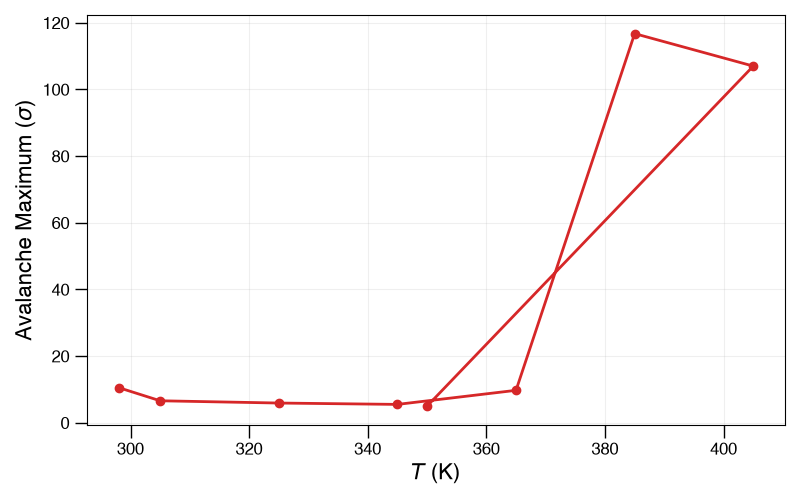

'""\nfig.savefig(\n    figure_path / \'avalanche_maximum_vs_temperature.pdf\',\n    format=\'pdf\',\n    dpi=300,\n    bbox_inches=\'tight\',\n    metadata={\'Creator\': \'\'},\n)\n'

In [17]:
# Avalanche rate per scan vs temperature (using same scan set)
scans = [219, 334, 552, 579, 709, 779, 796,868]
sigma_threshold = 3
min_separation = 15
%matplotlib widget


temps = []
maximum = []
scan_ids = []

for scan in scans:
    scan_path = config.get(f"{scan}")
    results_file = config.get(f"{scan}_results")
    temp = config.get(f"{scan}_temperature")

    if scan_path is None or results_file is None or temp is None:
        print(f"Scan {scan}: missing config entry, skipping")
        continue

    rpath = BASE_DIR / Path(scan_path) / Path(config.get("Results")) / Path(results_file)
    if not rpath.exists():
        print(f"Scan {scan}: file not found, skipping")
        continue

    with h5py.File(rpath, 'r') as DATA:
        C_scan = DATA['XPCS/TwoTime'][:]
        C_ext = DATA['XPCS/TwoTime_extent'][:]

    res = avalanche_from_C2(
        C_scan,
        m=15,
        sigma_threshold=sigma_threshold,
        min_separation=min_separation,
        min_prominence=0.0,
    )

    av_times = res['avalanche_times']
    if len(av_times) == 0:
        print(f"Scan {scan} ({temp} K): no avalanches found")
        continue

    magnitudes = np.asarray(res['A_norm'][av_times], dtype=float)
    magnitudes = magnitudes[np.isfinite(magnitudes)]
    magnitudes = magnitudes[magnitudes > 0]

    if magnitudes.size == 0:
        print(f"Scan {scan} ({temp} K): no positive magnitudes, skipping")
        continue

    n_events = len(res['avalanche_times'])
    total_time = float(C_ext[3] - C_ext[2])

    if total_time <= 0:
        print(f"Scan {scan} ({temp} K): non-positive duration, skipping")
        continue

    #rate = n_events / total_time  # events per second

    temps.append(float(temp))
    maximum.append(np.max(magnitudes))
    scan_ids.append(scan)

    print(f"Scan {scan} ({temp} K): maximum={maximum}, duration={total_time:.2f} s, rate={rate:.4f} s^-1")

if len(temps) == 0:
    raise RuntimeError("No valid scans for avalanche-rate plot.")

# Sort by temperature
#order = np.argsort(temps)
temps = np.asarray(temps)#[order]
maximum = np.asarray(maximum)#[order]
scan_ids = np.asarray(scan_ids)#[order]

fig, ax = plt.subplots(figsize=fig_size)
ax.plot(temps, maximum, 'o-', lw=2, color='tab:red')

#for T, r, sid in zip(temps, rates, scan_ids):
    #ax.annotate(str(sid), (T, r), xytext=(4, 4), textcoords='offset points', fontsize=8)

ax.set_xlabel('$T$ (K)',fontsize=ax_label_font)
ax.set_ylabel('Avalanche Maximum ($\sigma$)',fontsize=ax_label_font)
#ax.set_title('Avalanche Maximum vs Temperature',fontsize=ax_title_font)
ax.tick_params(which='major', length=major_tick_length, width=major_tick_width, labelsize=legend_ax_font)
ax.tick_params(which='minor', length=minor_tick_length, width=minor_tick_width,labelsize=legend_ax_font)

ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

"""""
fig.savefig(
    figure_path / 'avalanche_maximum_vs_temperature.pdf',
    format='pdf',
    dpi=300,
    bbox_inches='tight',
    metadata={'Creator': ''},
)
"""""